## Libraries and General Checks

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack
from scipy.sparse import csr_matrix

# Use a consistent style for all charts in this notebook.
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

print(f"Python: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__}")
print(f"pandas: {pd.__version__}")

print("\n✓ Environment check passed")

Python: 3.14.2
NumPy: 2.5.3
pandas: 3.0.5

✓ Environment check passed


---
## Splitting the CSV into the 'human' and 'ai' labels

In [2]:
# Load the dataset
df = pd.read_csv('../original_data/DataSet_AIvsHuman.csv')
df.head()

,id,prompt,content,type,source,label,topic,word_count,char_count,ai_model,language,complexity_score,is_multiline_code
0,1,Write a string manipulation solution in python,def string_manipulation():\n # TODO: implem...,code,blog,human,string manipulation,9,84,NaN,python,3,True
1,2,Explain health in simple terms,Experts recommend focusing on health to improv...,text,generated,ai,health,29,211,Claude,en,3,False
2,3,Summarize recent developments in finance,The development of finance technologies has ac...,text,generated,ai,finance,56,419,GPT-4,en,5,False
3,4,Summarize recent developments in finance,Recent studies show that finance can have sign...,text,generated,ai,finance,42,298,Claude,en,10,False
4,5,Provide a graph traversal algorithm in cpp,vector<int> arr; // graph traversal example\nf...,code,generated,ai,graph traversal,11,98,Gemini,cpp,10,True


In [3]:
#ai csv file
df_ai = df[df["label"].str.lower() == "ai"]
#df_ai.to_csv("../created_data/ai_only_file.csv", index=False)
df_ai.head()

#human csv file
df_human = df[df["label"].str.lower() == "human"]
#df_human.to_csv("../created_data/human_only_file.csv", index=False)
df_human.head()

,id,prompt,content,type,source,label,topic,word_count,char_count,ai_model,language,complexity_score,is_multiline_code
0,1,Write a string manipulation solution in python,def string_manipulation():\n # TODO: implem...,code,blog,human,string manipulation,9,84,NaN,python,3,True
5,6,Write a story about politics,politics has become increasingly important in ...,text,news,human,politics,48,354,NaN,en,9,False
6,7,Write a graph traversal solution in python,arr = [i for i in range(10)] # graph traversal...,code,news,human,graph traversal,11,54,NaN,python,8,False
7,8,Write a story about tech,Recent studies show that tech can have signifi...,text,news,human,tech,53,352,NaN,en,5,False
11,12,Write a graph traversal solution in java,public class graph_traversal {\n public sta...,code,github,human,graph traversal,16,120,NaN,java,1,True


## Splitting the data into 'code' or 'text'

rows, columns: (4937, 13)


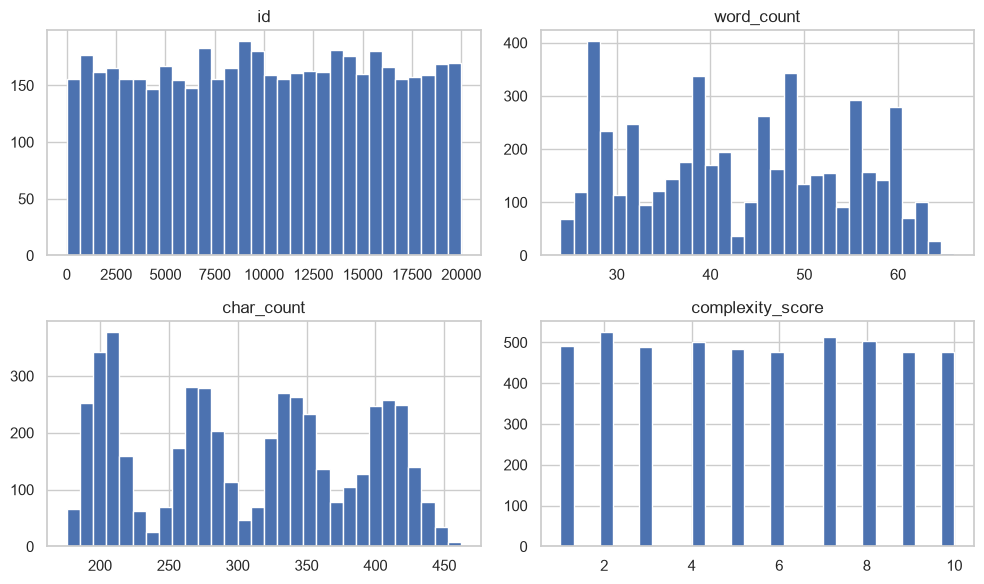

In [4]:
# human file
df_human.head()

#df_human.info()
#df_human.describe().T

# human_text file
df_humantext = df_human[df_human["type"].str.lower() == "text"]
#df_humantext.to_csv("../created_data/human_text_only.csv", index=False)
df_humantext.head()
print("rows, columns:", df_humantext.shape)
#df_humantext.info()

df_humantext.select_dtypes("number").hist(figsize=(10, 6), bins=30, edgecolor="white")
plt.tight_layout()
plt.show()

In [8]:
# ai file

#df_ai.head()

#df_ai.info()
#df_ai.describe().T

# ai_text file
df_aitext = df_ai[df_ai["type"].str.lower() == "text"]
#df_aitext.to_csv("../created_data/ai_text_only.csv", index=False)
df_aitext.head()
print("rows, columns:", df_aitext.shape)
#df_aitext.info()

rows, columns: (5067, 13)


rows, columns: (10004, 13)


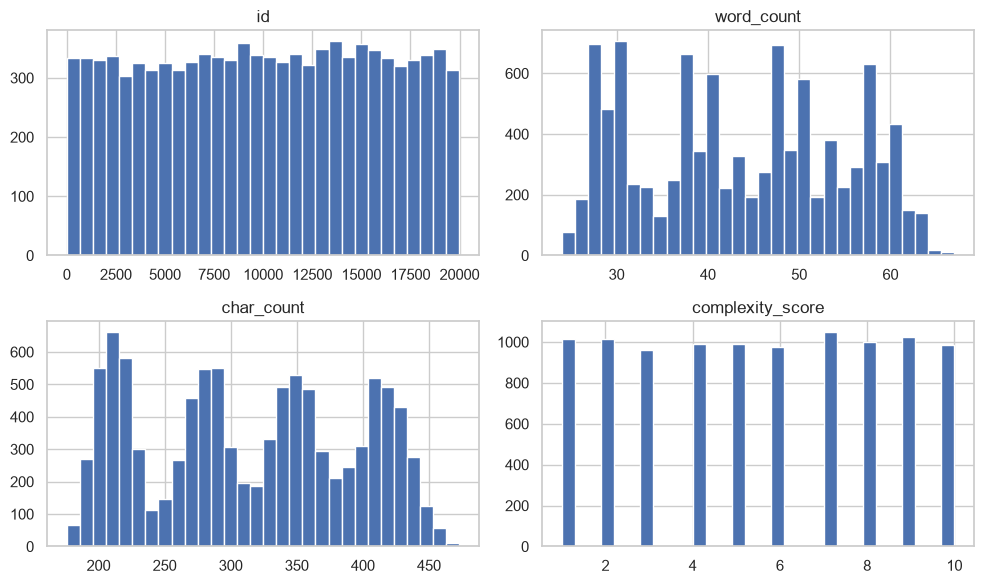

In [5]:
# standard df 
df_text = df[df["type"].str.lower() == "text"]
#df_text.to_csv("../created_data/hvsai_text_only.csv", index=False)
df_text.head()
print("rows, columns:", df_text.shape)
#df_text.info()

df_text.select_dtypes("number").hist(figsize=(10, 6), bins=30, edgecolor="white")
plt.tight_layout()
plt.show()

---
## First Look

In [ ]:
# shape returns (number_of_rows, number_of_columns).
print("rows, columns:", df.shape)
print("rows, columns:", df_ai.shape)
print("rows, columns:", df_human.shape)

# info() shows column names, data types, and non-missing value counts.
print('\nDataFrame Info:')
df.info()


# Count missing cells in each column.
missing = pd.DataFrame({
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(1),
})

# Sort so the columns needing the most attention appear first.
missing.sort_values("n_missing", ascending=False)

# duplicated() marks rows that are exact copies of an earlier row.
# sum() counts how many duplicate rows were found.
print("\nExact duplicate rows:", df.duplicated().sum())

# describe() calculates common summaries for numeric columns.
# Transpose so each variable appears as a row, which is easier to read.
df.describe().T

# Select numeric columns and draw one histogram for each.
df.select_dtypes("number").hist(figsize=(10, 6), bins=30, edgecolor="white")
plt.tight_layout()
plt.show()


# Select numeric columns and calculate Pearson correlations.
# Pearson is pandas' default method and measures linear relationships.
numeric_data = df.select_dtypes("number")
corr = numeric_data.corr(method="pearson")

# A heatmap makes positive and negative relationships easier to scan.
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, square=True, cbar_kws={"label": "Pearson correlation"})
plt.title("Pearson correlation matrix")
plt.tight_layout()
plt.show()

# ai data
numeric_data = df_ai.select_dtypes("number")
corr = numeric_data.corr(method="pearson")

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, square=True, cbar_kws={"label": "Pearson correlation"})
plt.title("Pearson correlation matrix")
plt.tight_layout()
plt.show()

# human data
numeric_data = df_human.select_dtypes("number")
corr = numeric_data.corr(method="pearson")

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, square=True, cbar_kws={"label": "Pearson correlation"})
plt.title("Pearson correlation matrix")
plt.tight_layout()
plt.show()

---
## Distribution of data

AI data

In [ ]:
# Compare four ways to show the distribution of one numeric column.
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))

sns.histplot(data=df_ai, x="char_count", bins=25, ax=axes[0])
axes[0].set_title("Histogram")

sns.boxplot(data=df_ai, y="char_count", ax=axes[1])
axes[1].set_title("Box plot")

sns.violinplot(data=df_ai, y="char_count", ax=axes[2])
axes[2].set_title("Violin")

sns.ecdfplot(data=df_ai, x="char_count", ax=axes[3])
axes[3].set_title("ECDF")

plt.tight_layout()
plt.show()

---
Human data

In [ ]:
# Compare four ways to show the distribution of one numeric column.
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))

sns.histplot(data=df_human, x="char_count", bins=25, ax=axes[0])
axes[0].set_title("Histogram")

sns.boxplot(data=df_human, y="char_count", ax=axes[1])
axes[1].set_title("Box plot")

sns.violinplot(data=df_human, y="char_count", ax=axes[2])
axes[2].set_title("Violin")

sns.ecdfplot(data=df_human, x="char_count", ax=axes[3])
axes[3].set_title("ECDF")

plt.tight_layout()
plt.show()

---
Combined data

In [ ]:
# Compare four ways to show the distribution of one numeric column.
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))

sns.histplot(data=df, x="char_count", bins=25, ax=axes[0])
axes[0].set_title("Histogram")

sns.boxplot(data=df, y="char_count", ax=axes[1])
axes[1].set_title("Box plot")

sns.violinplot(data=df, y="char_count", ax=axes[2])
axes[2].set_title("Violin")

sns.ecdfplot(data=df, x="char_count", ax=axes[3])
axes[3].set_title("ECDF")

plt.tight_layout()
plt.show()

---
## Comparisons

AI data

In [ ]:
# Compare a summary plot, a spread plot, and the individual observations.
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))

sns.barplot(data=df_ai, x="ai_model", y="char_count", errorbar=None, ax=axes[0])
axes[0].set_title("Bar of means: hides everything")

sns.boxplot(data=df_ai, x="ai_model", y="char_count", ax=axes[1])
axes[1].set_title("Box: shows spread")

sns.stripplot(data=df_ai, x="ai_model", y="char_count", alpha=0.5, ax=axes[2])
axes[2].set_title("Every input: shows the truth")

plt.tight_layout()
plt.show()

---
Human data

In [ ]:
# Compare a summary plot, a spread plot, and the individual observations.
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))

sns.barplot(data=df_human, x="source", y="complexity_score", errorbar=None, ax=axes[0])
axes[0].set_title("Bar of means: hides everything")

sns.boxplot(data=df_human, x="source", y="complexity_score", ax=axes[1])
axes[1].set_title("Box: shows spread")

sns.stripplot(data=df_human, x="source", y="complexity_score", alpha=0.5, ax=axes[2])
axes[2].set_title("Every input: shows the truth")

plt.tight_layout()
plt.show()

---
All data

In [ ]:
# Compare a summary plot, a spread plot, and the individual observations.
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))

sns.barplot(data=df, x="label", y="char_count", errorbar=None, ax=axes[0])
axes[0].set_title("Bar of means: hides everything")

sns.boxplot(data=df, x="label", y="char_count", ax=axes[1])
axes[1].set_title("Box: shows spread")

sns.stripplot(data=df, x="label", y="char_count", alpha=0.5, ax=axes[2])
axes[2].set_title("Every input: shows the truth")

plt.tight_layout()
plt.show()

---
## Relationship: do two variables move together?

When your question is **“Is X associated with Y?”**, start with a scatter plot.

Here we compare bill length and bill depth. The displayed `r` value is **Pearson correlation**, the default method used by pandas. It measures a straight-line relationship, not every possible kind of association. First look at the overall pattern; then split by species.

In [ ]:
# Remove rows missing either variable before calculating correlations.
sub = df.dropna(subset=["char_count", "word_count"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: the overall relationship across all penguins.
# corr() uses Pearson correlation by default, so the line measures linear association.
sns.regplot(data=sub, x="char_count", y="word_count",
            scatter_kws={"alpha": 0.6}, line_kws={"color": "black"}, ax=axes[0])
axes[0].set_title(f"(Pearson r = {sub['char_count'].corr(method='pearson', other=sub['word_count']):.2f})")

# Right: draw one fitted line for each species.
for sp, g in sub.groupby("label"):
    sns.regplot(data=g, x="char_count", y="word_count",
                scatter_kws={"alpha": 0.6}, label=sp, ax=axes[1])
axes[1].legend(title="label")
axes[1].set_title("By label: every slope flips")

plt.tight_layout()
plt.show()

print("overall: ", round(sub["char_count"].corr(method="pearson", other=sub["word_count"]), 3))
for sp, g in sub.groupby("label"):
    print(f"{sp:12s}", round(g["char_count"].corr(method="pearson", other=g["word_count"]), 3))

---
## Preprocessing & Feature Engineering

Libraries and Impoets for preprocessing

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer

In [9]:
# checking for duplicate content

print("Number of duplicate content rows:", df_text.duplicated(subset=["content"]).sum())
print("Number of duplicate content rows for ai:", df_aitext.duplicated(subset=["content"]).sum())
print("Number of duplicate content rows for human:", df_humantext.duplicated(subset=["content"]).sum())

print("exact duplicate rows:", df_text.duplicated().sum())

conflicting_content = (
    df_text.groupby("content")["label"]
      .nunique()
      .reset_index()
)

conflicting_content = conflicting_content[
    conflicting_content["label"] > 1
]

print(f"Number of conflicting texts: {len(conflicting_content)}")


Number of duplicate content rows: 1812
Number of duplicate content rows for ai: 925
Number of duplicate content rows for human: 887
exact duplicate rows: 0
Number of conflicting texts: 0


### Removing duplicate content

In [10]:
# Check duplicates
print(df_text.duplicated(subset=["content"]).sum())

# Remove duplicates
df_text = df_text.drop_duplicates(subset=["content"])

# Verify
print(df_text.duplicated(subset=["content"]).sum())
print(df_text.shape)

#df_text.to_csv("../created_data/hvsai_text_only.csv", index=False)

1812
0
(8192, 13)


In [ ]:
# Check duplicates
print(df_text.duplicated(subset=["prompt"]).sum())


In [ ]:
print("Number of duplicate prompt rows:", df_text.duplicated(subset=["prompt"]).sum())
print("Number of duplicate prompt rows for ai:", df_aitext.duplicated(subset=["prompt"]).sum())
print("Number of duplicate prompt rows for human:", df_humantext.duplicated(subset=["prompt"]).sum())

conflicting_prompts = (
    df_text.groupby("prompt")["label"]
      .nunique()
      .reset_index()
)

conflicting_prompts = conflicting_prompts[
    conflicting_prompts["label"] > 1
]

print(f"Number of conflicting texts: {len(conflicting_content)}")

might be a good idea to remove prompts as a leaky column as the model could learn certain prompts mean ai or human

In [ ]:
# Checking for source info
print("AI Text Source Info:")
print(df_aitext['source'].value_counts(dropna=False))
print("\nHuman Text Source Info:")
print(df_humantext['source'].value_counts(dropna=False))

print("\nLanguage Info:")
print(df_text['language'].value_counts(dropna=False))
print("\nType Info:")
print(df_text['type'].value_counts(dropna=False))

print("\nMultiline Code Info:")
print(df_text['is_multiline_code'].value_counts(dropna=False))

Source seems to be a leaky column due to the text sources being different for the ai content vs the human content

Will be removing language, multiline code, and type in 'leaky columns' just because english is the only option and so it is useless.

In [ ]:
# Checking for topic info
print("AI Text Topic Info:")
print(df_aitext['topic'].value_counts(dropna=False))
print("\nHuman Text Topic Info:")
print(df_humantext['topic'].value_counts(dropna=False))

Topics are not leaky because they have the same topic info

## Target and features — check for target leakage

We want to predict `label`.

**Think:** for every column, ask *would this be available **before** we know the satisfaction score?*

- Which column only exists **because of** the outcome? That is **target leakage**: remove that column.
- Which column carries no information at all and should not be a feature?

In [11]:
target = "label"

leaky_cols = ["source", "ai_model", "language", "type", "is_multiline_code", "prompt"]
id_cols = ["id"]

X = df_text.drop(columns=[target] + leaky_cols + id_cols)
y = df_text[target]
print("Features used:", X.columns.tolist())

# X (leakagefree_data.csv) removes the 'label', 'source', 'ai_model', and 'id' columns.

#X.to_csv("../created_data/leakagefree_textonly.csv", index=False)
X.head()

Features used: ['content', 'topic', 'word_count', 'char_count', 'complexity_score']


,content,topic,word_count,char_count,complexity_score
1,Experts recommend focusing on health to improv...,health,29,211,3
2,The development of finance technologies has ac...,finance,56,419,5
3,Recent studies show that finance can have sign...,finance,42,298,10
5,politics has become increasingly important in ...,politics,48,354,9
7,Recent studies show that tech can have signifi...,tech,53,352,5


Checked for missing values and outliers but none are present

# Feature engineering

Create **at least two new features** that could plausibly help predict whether it is ai generated or not. Write one sentence per feature explaining why.

In [ ]:
# Not added yet as the new features added may be more useful.
def add_features(data):
    # Work on a copy, so the same function is safe for either split.
    result = data.copy()

    result["char_per_word"] = (result["char_count"] / result["word_count"]).round(1)


    # Age groups are categories, not numeric scores; they will be one-hot encoded later.
    result["word_count_length"] = pd.cut(
        result["word_count"], bins=[0, 29, 49, np.inf],
        labels=["small", "medium", "large"],
    ).astype("object")
    return result

# The recipe is fixed, so apply it identically to train and test data.
Xtr = add_features(Xtr)
Xte = add_features(Xte)
Xtr[["word_count_length"]]
Xtr['word_count_length'].value_counts(dropna=False)
Xte[["word_count_length"]].value_counts(dropna=False)


## Maybe adding features?

> based of this article: https://socialsci.libretexts.org/Bookshelves/Anthropology/Cultural_Anthropology/Cultural_Anthropology_(Wikibook)/4%3A_Communication_and_Language/4.4%3A_Features_of_Language 

> 'Basic Features of Language'

human_text_only data

In [ ]:
# Human Text Only Data
# Load CSV
df_humantext = pd.read_csv("../created_data/human_text_only.csv")

# Count unique words in each content entry
df_humantext["unique_word_count"] = df_humantext["content"].fillna("").apply(
    lambda text: len(
        set(
            re.findall(r"\b\w+\b", text.lower())
        )
    )
)

# Sentence count
df_humantext["sentence_count"] = df_humantext["content"].fillna("").apply(
    lambda x: len([s for s in re.split(r"[.!?]+", str(x)) if s.strip()])
)

# Unique word ratio
# A low value (e.g. 0.3-0.5) indicates lots of repeated words.
# A high value (e.g. 0.8-1.0) indicates a more varied vocabulary.
df_humantext["unique_word_ratio"] = df_humantext["unique_word_count"] / df_humantext["word_count"].replace(0, 1)

# Average word length
df_humantext["avg_word_length"] = df_humantext["content"].fillna("").apply(
    lambda x: (
        sum(len(word) for word in re.findall(r"\b\w+\b", str(x)))
        / max(len(re.findall(r"\b\w+\b", str(x))), 1)
    )
)

# long word ratio
df_humantext["long_word_ratio"] = df_humantext["content"].fillna("").apply(
    lambda x: (
        sum(1 for word in re.findall(r"\b\w+\b", str(x)) if len(word) > 6)
        / max(len(re.findall(r"\b\w+\b", str(x))), 1)
    )
)

# short word ratio
df_humantext["short_word_ratio"] = df_humantext["content"].fillna("").apply(
    lambda x: (
        sum(1 for word in re.findall(r"\b\w+\b", str(x)) if len(word) <= 3)
        / max(len(re.findall(r"\b\w+\b", str(x))), 1)
    )
)

# punctuation count
df_humantext["punctuation_count"] = df_humantext["content"].fillna("").apply(
    lambda x: len(re.findall(r"[^\w\s]", str(x)))
)

# punctuation ratio
df_humantext["punctuation_ratio"] = df_humantext["content"].fillna("").apply(
    lambda x: len(re.findall(r"[^\w\s]", str(x)))
) / df_humantext["char_count"].replace(0, 1)

# word length standard deviation
df_humantext["word_length_std"] = df_humantext["content"].fillna("").apply(
    lambda text: np.std([
        len(word) for word in re.findall(r"\b[A-Za-z']+\b", str(text))
    ]) if re.findall(r"\b[A-Za-z']+\b", str(text)) else 0
)

# common word ratio
common_words = {
    "a", "an", "the", "and", "or", "but", "if", "is", "are", "was",
    "were", "be", "been", "being", "to", "of", "in", "on", "for",
    "with", "as", "at", "by", "from", "that", "this", "it"
}

df_humantext["commonword_ratio"] = df_humantext["content"].fillna("").apply(
    lambda text: (
        lambda words: (
            sum(word in common_words for word in words) / len(words)
            if words else 0
        )
    )(re.findall(r"\b[A-Za-z']+\b", str(text).lower()))
)

# semi-colon ratio (looked at adding it as a feature but both files had zero semicolons)

# results visualised
df_humantext.select_dtypes("number").hist(figsize=(10, 6), bins=30, edgecolor="white")
plt.tight_layout()
plt.show()

print("rows, columns:", df_humantext.shape)


ai_text_only

In [ ]:
# AI Text Only Data
# Load CSV
df_aitext = pd.read_csv("../created_data/ai_text_only.csv")

# Count unique words in each content entry
df_aitext["unique_word_count"] = df_aitext["content"].fillna("").apply(
    lambda text: len(
        set(
            re.findall(r"\b\w+\b", text.lower())
        )
    )
)

# Sentence count
df_aitext["sentence_count"] = df_aitext["content"].fillna("").apply(
    lambda x: len([s for s in re.split(r"[.!?]+", str(x)) if s.strip()])
)

df_aitext.to_csv("../created_data/ai_text_only.csv", index=False)

# Unique word ratio
# A low value (e.g. 0.3-0.5) indicates lots of repeated words.
# A high value (e.g. 0.8-1.0) indicates a more varied vocabulary.
df_aitext["unique_word_ratio"] = df_aitext["unique_word_count"] / df_aitext["word_count"].replace(0, 1)

# Average word length
df_aitext["avg_word_length"] = df_aitext["content"].fillna("").apply(
    lambda x: (
        sum(len(word) for word in re.findall(r"\b\w+\b", str(x)))
        / max(len(re.findall(r"\b\w+\b", str(x))), 1)
    )
)

# long word ratio
df_aitext["long_word_ratio"] = df_aitext["content"].fillna("").apply(
    lambda x: (
        sum(1 for word in re.findall(r"\b\w+\b", str(x)) if len(word) > 6)
        / max(len(re.findall(r"\b\w+\b", str(x))), 1)
    )
)

# short word ratio
df_aitext["short_word_ratio"] = df_aitext["content"].fillna("").apply(
    lambda x: (
        sum(1 for word in re.findall(r"\b\w+\b", str(x)) if len(word) <= 3)
        / max(len(re.findall(r"\b\w+\b", str(x))), 1)
    )
)

# punctuation count
df_aitext["punctuation_count"] = df_aitext["content"].fillna("").apply(
    lambda x: len(re.findall(r"[^\w\s]", str(x)))
)

# punctuation ratio
df_aitext["punctuation_ratio"] = df_aitext["content"].fillna("").apply(
    lambda x: len(re.findall(r"[^\w\s]", str(x)))
) / df_aitext["char_count"].replace(0, 1)

# word length standard deviation
df_aitext["word_length_std"] = df_aitext["content"].fillna("").apply(
    lambda text: np.std([
        len(word) for word in re.findall(r"\b[A-Za-z']+\b", str(text))
    ]) if re.findall(r"\b[A-Za-z']+\b", str(text)) else 0
)

# common word ratio
common_words = {
    "a", "an", "the", "and", "or", "but", "if", "is", "are", "was",
    "were", "be", "been", "being", "to", "of", "in", "on", "for",
    "with", "as", "at", "by", "from", "that", "this", "it"
}

df_aitext["commonword_ratio"] = df_aitext["content"].fillna("").apply(
    lambda text: (
        lambda words: (
            sum(word in common_words for word in words) / len(words)
            if words else 0
        )
    )(re.findall(r"\b[A-Za-z']+\b", str(text).lower()))
)

# semi-colon ratio (looked at adding it as a feature but both files had zero semicolons)

# results visualised
df_aitext.select_dtypes("number").hist(figsize=(10, 6), bins=30, edgecolor="white")
plt.tight_layout()
plt.show()

print("rows, columns:", df_aitext.shape)

ai + human text only file

In [ ]:
# Human vs AI Text Only Data
# Load CSV
df_text = pd.read_csv("../created_data/hvsai_text_only.csv")

# Count unique words in each content entry
df_text["unique_word_count"] = df_text["content"].fillna("").apply(
    lambda text: len(
        set(
            re.findall(r"\b\w+\b", text.lower())
        )
    )
)

# Sentence count
df_text["sentence_count"] = df_text["content"].fillna("").apply(
    lambda x: len([s for s in re.split(r"[.!?]+", str(x)) if s.strip()])
)

# Unique word ratio
# A low value (e.g. 0.3-0.5) indicates lots of repeated words.
# A high value (e.g. 0.8-1.0) indicates a more varied vocabulary.
df_text["unique_word_ratio"] = df_text["unique_word_count"] / df_text["word_count"].replace(0, 1)

# Average word length
df_text["avg_word_length"] = df_text["content"].fillna("").apply(
    lambda x: (
        sum(len(word) for word in re.findall(r"\b\w+\b", str(x)))
        / max(len(re.findall(r"\b\w+\b", str(x))), 1)
    )
)

# long word ratio
df_text["long_word_ratio"] = df_text["content"].fillna("").apply(
    lambda x: (
        sum(1 for word in re.findall(r"\b\w+\b", str(x)) if len(word) > 6)
        / max(len(re.findall(r"\b\w+\b", str(x))), 1)
    )
)

# short word ratio
df_text["short_word_ratio"] = df_text["content"].fillna("").apply(
    lambda x: (
        sum(1 for word in re.findall(r"\b\w+\b", str(x)) if len(word) <= 3)
        / max(len(re.findall(r"\b\w+\b", str(x))), 1)
    )
)

# punctuation count
df_text["punctuation_count"] = df_text["content"].fillna("").apply(
    lambda x: len(re.findall(r"[^\w\s]", str(x)))
)

# punctuation ratio
df_text["punctuation_ratio"] = df_text["content"].fillna("").apply(
    lambda x: len(re.findall(r"[^\w\s]", str(x)))
) / df_text["char_count"].replace(0, 1)

# word length standard deviation
df_text["word_length_std"] = df_text["content"].fillna("").apply(
    lambda text: np.std([
        len(word) for word in re.findall(r"\b[A-Za-z']+\b", str(text))
    ]) if re.findall(r"\b[A-Za-z']+\b", str(text)) else 0
)

# common word ratio
common_words = {
    "a", "an", "the", "and", "or", "but", "if", "is", "are", "was",
    "were", "be", "been", "being", "to", "of", "in", "on", "for",
    "with", "as", "at", "by", "from", "that", "this", "it"
}

df_text["commonword_ratio"] = df_text["content"].fillna("").apply(
    lambda text: (
        lambda words: (
            sum(word in common_words for word in words) / len(words)
            if words else 0
        )
    )(re.findall(r"\b[A-Za-z']+\b", str(text).lower()))
)

# semi-colon ratio (looked at adding it as a feature but both files had zero semicolons)

# results visualised
df_text.select_dtypes("number").hist(figsize=(10, 6), bins=30, edgecolor="white")
plt.tight_layout()
plt.show()

print("rows, columns:", df_text.shape)

leakage free data + features

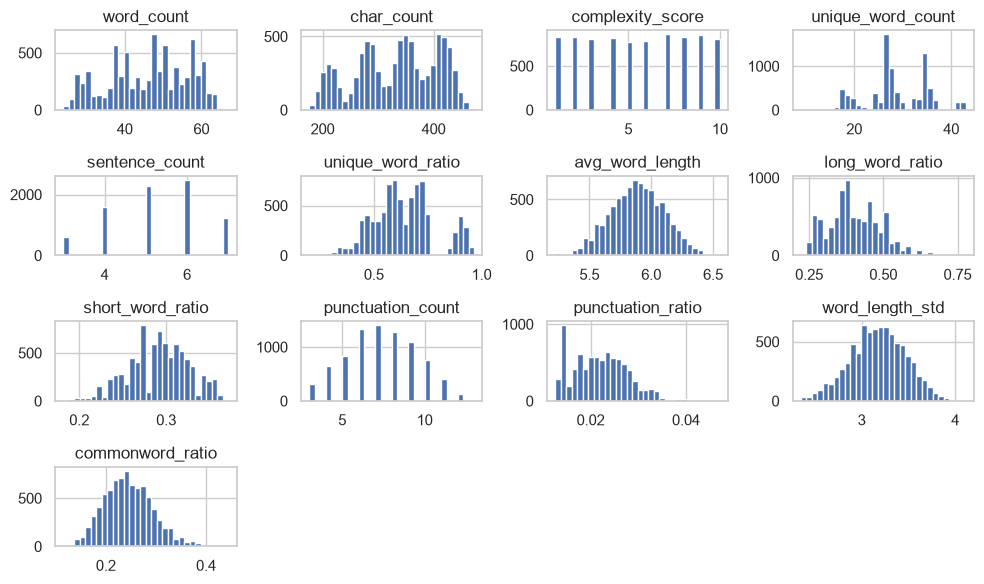

rows, columns: (8192, 15)


In [12]:
# Human vs AI Text Only Leakage Free Data
# Load CSV
#X = pd.read_csv("../created_data/leakagefree_textonly.csv")

# Count unique words in each content entry
X["unique_word_count"] = X["content"].fillna("").apply(
    lambda text: len(
        set(
            re.findall(r"\b\w+\b", text.lower())
        )
    )
)


# Sentence count
X["sentence_count"] = X["content"].fillna("").apply(
    lambda x: len([s for s in re.split(r"[.!?]+", str(x)) if s.strip()])
)

# Unique word ratio
# A low value (e.g. 0.3-0.5) indicates lots of repeated words.
# A high value (e.g. 0.8-1.0) indicates a more varied vocabulary.
X["unique_word_ratio"] = X["unique_word_count"] / X["word_count"].replace(0, 1)


# Average word length
X["avg_word_length"] = X["content"].fillna("").apply(
    lambda x: (
        sum(len(word) for word in re.findall(r"\b\w+\b", str(x)))
        / max(len(re.findall(r"\b\w+\b", str(x))), 1)
    )
)

# long word ratio
X["long_word_ratio"] = X["content"].fillna("").apply(
    lambda x: (
        sum(1 for word in re.findall(r"\b\w+\b", str(x)) if len(word) > 6)
        / max(len(re.findall(r"\b\w+\b", str(x))), 1)
    )
)

# short word ratio
X["short_word_ratio"] = X["content"].fillna("").apply(
    lambda x: (
        sum(1 for word in re.findall(r"\b\w+\b", str(x)) if len(word) <= 3)
        / max(len(re.findall(r"\b\w+\b", str(x))), 1)
    )
)

# punctuation count
X["punctuation_count"] = X["content"].fillna("").apply(
    lambda x: len(re.findall(r"[^\w\s]", str(x)))
)

# punctuation ratio
X["punctuation_ratio"] = X["punctuation_count"] / X["char_count"].replace(0, 1)

# word length standard deviation (variation in the number of words per sentence)
X["word_length_std"] = X["content"].fillna("").apply(
    lambda text: np.std([
        len(word) for word in re.findall(r"\b[A-Za-z']+\b", str(text))
    ]) if re.findall(r"\b[A-Za-z']+\b", str(text)) else 0
)

# common word ratio
common_words = {
    "a", "an", "the", "and", "or", "but", "if", "is", "are", "was",
    "were", "be", "been", "being", "to", "of", "in", "on", "for",
    "with", "as", "at", "by", "from", "that", "this", "it"
}

X["commonword_ratio"] = X["content"].fillna("").apply(
    lambda text: (
        lambda words: (
            sum(word in common_words for word in words) / len(words)
            if words else 0
        )
    )(re.findall(r"\b[A-Za-z']+\b", str(text).lower()))
)

#X.to_csv("../created_data/leakagefree_textonly.csv", index=False)

# semi-colon ratio (looked at adding it as a feature but both files had zero semicolons)

# results visualised
X.select_dtypes("number").hist(figsize=(10, 6), bins=30, edgecolor="white")
plt.tight_layout()
plt.show()

print("rows, columns:", X.shape)

# Train / test split

From here on, **anything that learns from the data is fitted on `X_train` only** and then applied to `X_test`.

The test set is looked at **once, at the end**.

In [13]:
# Keep 20% of the rows aside. random_state makes this split reproducible.
# Created from 'leakagefree_data.csv'
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("train:", X_train.shape, " test:", X_test.shape)

# Sections 5-10 change Xtr/Xte. These copies keep X_train/X_test untouched
# for the all-in-one pipeline in section 11.
#Xtr, Xte = X_train.copy(), X_test.copy()

#X_train.to_csv("../created_data/training_data_pipeline.csv", index=False)
#X_test.to_csv("../created_data/testing_data_pipeline.csv", index=False)


train: (6553, 15)  test: (1639, 15)


# Encoding categorical variables

- **Ordinal** → `OrdinalEncoder` with the categories in an **explicit order**. (Don't use `LabelEncoder` — it sorts alphabetically and is meant for targets.)
- **Nominal** → `OneHotEncoder(handle_unknown="ignore")`, so a category that only appears in the test set doesn't crash the model.

Fit the encoders on `Xtr`, transform both.

In [ ]:
# This column not working, need to figure out why



# This order is meaningful, so education is an ordinal variable.
#length_order = ["small", "medium", "large"]
#length_encoder = OrdinalEncoder(categories=[length_order])

# fit_transform learns the order from the training configuration and encodes training rows.
#Xtr[["word_count_length"]] = length_encoder.fit_transform(Xtr[["word_count_length"]])

# transform applies exactly the same mapping to the test rows.
#Xte[["word_count_length"]] = length_encoder.transform(Xte[["word_count_length"]])


In [14]:
# These columns have no meaningful numeric order, so create separate 0/1 columns.
nominal_cols = ["topic"]
nominal_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)


In [15]:

# Learn which category columns exist from training data only.
train_nominal = pd.DataFrame(
    nominal_encoder.fit_transform(X_train[nominal_cols]),
    columns=nominal_encoder.get_feature_names_out(nominal_cols), index=X_train.index,
)
print("train_nominal shape:", train_nominal.shape)

train_nominal shape: (6553, 6)


In [16]:

# Unsure what that did

# An unseen test category is ignored rather than causing an error.
test_nominal = pd.DataFrame(
    nominal_encoder.transform(X_test[nominal_cols]),
    columns=nominal_encoder.get_feature_names_out(nominal_cols), index=X_test.index,
)

# Replace the original text columns with their new numeric columns.
X_train = pd.concat([X_train.drop(columns=nominal_cols), train_nominal], axis=1)
X_test = pd.concat([X_test.drop(columns=nominal_cols), test_nominal], axis=1)
print("Columns after encoding:", X_train.shape[1])

#X_train.to_csv("../data/training_data.csv", index=False)


Columns after encoding: 20


In [ ]:

#Xtr.to_csv("../created_data/training_data.csv", index=False)

In [ ]:
#Xte.to_csv("../created_data/testing_data.csv", index=False)

# Scaling numerical variables

Some columns use very different units. For example, age might be around 20-80, while annual income can be tens of thousands. A later algorithm could treat income as more important simply because its numbers are larger.

**Standardisation** changes each numeric column so that its training values are centred around 0 and use a comparable scale. It does not change which values are relatively high or low within a column.

The code below:

1. compares the original ranges;
2. learns a mean and standard deviation from the training data; and
3. uses those same training values to standardise both the training and test sets.

The one-hot columns already contain only 0 and 1, so we leave them unchanged.

> Scale numbers if we end up using Logistic Regression or kNN. Do not scale if we use Random Forest or Decision Tree.

In [18]:
# One-hot columns are already 0/1, so scale only continuous or count-based variables.
numeric_cols = ["word_count",
    "char_count",
    "complexity_score",
    "unique_word_count",
    "sentence_count",
    "unique_word_ratio",
    "avg_word_length",
    "long_word_ratio",
    "short_word_ratio",
    "punctuation_count",
    "punctuation_ratio",
    "word_length_std",
    "commonword_ratio",
]
print("Ranges before scaling:")
print(X_train[numeric_cols].agg(["min", "max"]))

# The scaler learns the mean and standard deviation from training data only.
scaler = StandardScaler()
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])

# The test set uses those same training values; it must not calculate new ones.
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

print("\nTraining means after scaling:")
print(X_train[numeric_cols].mean().round(2))

Ranges before scaling:
     word_count  char_count  complexity_score  unique_word_count  \
min          24         176                 1                  9   
max          67         473                10                 43   

     sentence_count  unique_word_ratio  avg_word_length  long_word_ratio  \
min               3           0.200000         5.222222         0.222222   
max               7           0.965517         6.555556         0.777778   

     short_word_ratio  punctuation_count  punctuation_ratio  word_length_std  \
min          0.181818                  3           0.012552         2.349609   
max          0.371429                 13           0.047120         4.112612   

     commonword_ratio  
min          0.115385  
max          0.444444  

Training means after scaling:
word_count           0.0
char_count          -0.0
complexity_score     0.0
unique_word_count    0.0
sentence_count       0.0
unique_word_ratio    0.0
avg_word_length      0.0
long_word_ratio      0.0

In [ ]:
#Xtr.to_csv("../created_data/training_data.csv", index=False)

At this point the preprocessing pipeline looks like:

|✅ Removed leakage columns
|✅ Added handcrafted features
|✅ Train/test split performed
|✅ One-hot encoded topics
|✅ Scaled numerical features

The next major step is fitting TF-IDF on the training content column only and then combining those TF-IDF features with your scaled numerical features for modelling.

# Doing the same preparation with a pipeline

So far, we have prepared the data one step at a time: fill missing values, extract date information, create new features, encode categories, and scale numeric columns.

A **pipeline** is simply a saved checklist of those steps. Instead of writing and running each step separately every time, we put the steps in the correct order once and ask Python to run that checklist for us.

When we run `fit_transform(X_train)`, the pipeline learns any required values, such as medians and category lists, from the training data and prepares it. When we run `transform(X_test)`, it follows the exact same checklist for the test data but reuses the values learned from training.

This keeps our preparation consistent and prevents us from accidentally learning from the test data. It is still only data preparation; we are not building a predictive model yet.

In [ ]:
def row_wise_features(data):
    """Create features using each row only; no dataset-wide values are learned here."""
    result = data.copy()

    # Turn one date column into two numeric calendar features.
    #dates = pd.to_datetime(result["survey_date"], errors="coerce")
    #result["survey_month"] = dates.dt.month
    #result["survey_dayofweek"] = dates.dt.dayofweek

    # Create ratios before scaling, while values still use their original units.
    result["char_per_word"] = (
        result["char_count"] / result["word_count"]).round(1)
    

     # Keep age (word count) bands as categories; the nominal pipeline will encode them.
    result["word_count_length"] = pd.cut(
        result["word_count"], bins=[0, 29, 49, np.inf],
        labels=["small", "medium", "large"],
        ).astype("object")
    return result

# Assign each column to the type of preprocessing it needs.
numeric_cols = [
    "word_count", "char_count", "complexity_score", "char_per_word",
]
ordinal_cols = ["word_count_length"]
nominal_cols = ["topic", "language", "type", "is_multiline_code"]
length_order = ["small", "medium", "large"]
---
# For numeric data: fill gaps with training medians, then put columns on a common scale.
numeric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

# For education: fill gaps, then encode the supplied meaningful order.
ordinal_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OrdinalEncoder(categories=[length_order])),
])

# For nominal data: label missing values and create a 0/1 column for each category.
nominal_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encode", OneHotEncoder(handle_unknown="ignore")),
])

# Send each group of columns through its appropriate mini-pipeline.
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("ord", ordinal_pipeline, ordinal_cols),
    ("nom", nominal_pipeline, nominal_cols),
])

# First create features, then preprocess the resulting columns.
preprocessing_pipeline = Pipeline([
    ("features", FunctionTransformer(row_wise_features)),
    ("preprocess", preprocessor),
])

# fit_transform learns every required value from the training data and transforms it.
X_train_prepared = preprocessing_pipeline.fit_transform(X_train)

# transform applies those already-learned values to the unseen test data.
X_test_prepared = preprocessing_pipeline.transform(X_test)
print("Prepared train shape:", X_train_prepared.shape)
print("Prepared test shape: ", X_test_prepared.shape)

## TF-IDF 
> https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfTransformer.html

Term Frequency-Inverse Document Frequency (TF-IDF) is a text vectorisation technique that converts documents into numerical feature vectors. The approach assigns high weights to terms that occur frequently within a document but infrequently across the corpus, thereby highlighting words that are more discriminative for classification tasks. TF-IDF is widely used in information retrieval and text classification because it reduces the influence of very common words while emphasising terms that help distinguish between documents.

In [19]:
# Step 1: Createing the TF-IDF vectoriser 
tfidf = TfidfVectorizer(
    analyzer="char",    # Uses character sequences instead of words.
    ngram_range=(3, 5),
    max_features=10000,
    min_df=3,
    sublinear_tf=True
)

# Step 2: Fit only on the training text
X_train_tfidf = tfidf.fit_transform(
    X_train["content"].fillna("")
)

# Step 3: Transform the test data
X_test_tfidf = tfidf.transform(
    X_test["content"].fillna("")
)

# Step 4: Check the result
print("X_train_tfidf shape:", X_train_tfidf.shape)
print("X_test_tfidf shape:", X_test_tfidf.shape)

# 8003/2001 training documents
# 1296/1296 TF-IDF features

# Step 5: Combine with your scaled features
feature_columns = [
    "word_count",
    "char_count",
    "complexity_score",
    "unique_word_count",
    "sentence_count",
    "unique_word_ratio",
    "avg_word_length",
    "long_word_ratio",
    "short_word_ratio",
    "punctuation_count",
    "punctuation_ratio",
    "word_length_std",
    "commonword_ratio",
    "topic_education",
    "topic_finance",
    "topic_health",
    "topic_politics",
    "topic_sports",
    "topic_tech"
]


X_train_numeric = csr_matrix(
    X_train[feature_columns].to_numpy()
)
print("X_train_numeric shape:", X_train_numeric.shape)

X_test_numeric = csr_matrix(
    X_test[feature_columns].to_numpy()
)
print("X_test_numeric shape:", X_test_numeric.shape)

X_train_final = hstack([
    X_train_tfidf,
    X_train_numeric
])
print("X_train_final shape:", X_train_final.shape)

X_test_final = hstack([
    X_test_tfidf,
    X_test_numeric
])
print("X_test_final shape:", X_test_final.shape)

pd.DataFrame(
    X_train_final[:5].toarray()
).head()

X_train_tfidf shape: (6553, 1296)
X_test_tfidf shape: (1639, 1296)
X_train_numeric shape: (6553, 19)
X_test_numeric shape: (1639, 19)
X_train_final shape: (6553, 1315)
X_test_final shape: (1639, 1315)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,...,1290,1291,1292,1293,1294,1295,1296,1297,1298,1299,1300,1301,1302,1303,1304,1305,1306,1307,1308,1309,1310,1311,1312,1313,1314
0,0.000000,0.000000,0.000000,0.034995,0.034995,0.034995,0.000000,0.000000,0.000000,0.043864,0.043864,0.043864,0.000000,0.000000,0.000000,0.049321,0.034995,0.034995,0.034995,0.034995,0.103994,0.103994,0.103994,0.000000,0.000000,...,0.0,0.068643,0.0,0.072091,0.0,0.0,0.872695,0.716464,-0.538501,-1.341185,-0.228400,-1.913253,0.121226,-0.442046,-1.070604,-1.050578,-1.589032,-0.426078,-0.554937,1.0,0.0,0.0,0.0,0.0,0.0
1,0.024628,0.024628,0.024628,0.021291,0.021291,0.021291,0.035813,0.035813,0.035813,0.021531,0.021531,0.021531,0.021218,0.021218,0.021218,0.036049,0.021291,0.021291,0.021291,0.021291,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.000000,0.0,0.000000,0.0,0.0,1.067109,1.263528,-0.886990,2.269655,1.507918,0.828666,0.308252,0.352336,0.243518,1.744754,0.664854,0.043493,-0.431771,0.0,0.0,0.0,1.0,0.0,0.0
2,0.022398,0.022398,0.022398,0.040637,0.040637,0.040637,0.019237,0.019237,0.019237,0.033155,0.033155,0.033155,0.000000,0.000000,0.000000,0.054059,0.040637,0.040637,0.040637,0.040637,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.064310,0.0,0.067540,0.0,0.0,1.747557,1.755885,1.552432,0.071753,1.507918,-1.285305,-0.086581,-0.442046,0.331126,1.278865,-0.068432,0.043078,-0.612780,0.0,0.0,0.0,1.0,0.0,0.0
3,0.027815,0.027815,0.027815,0.000000,0.000000,0.000000,0.023889,0.023889,0.023889,0.024317,0.024317,0.024317,0.040574,0.040574,0.040574,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.026395,0.026395,...,0.0,0.000000,0.0,0.000000,0.0,0.0,0.095041,0.128370,0.506965,1.013711,0.639759,0.760564,-0.209569,-0.399754,-0.169492,0.812977,0.743265,0.213530,0.533840,0.0,0.0,1.0,0.0,0.0,0.0
4,0.000000,0.000000,0.000000,0.035159,0.035159,0.035159,0.000000,0.000000,0.000000,0.044070,0.044070,0.044070,0.000000,0.000000,0.000000,0.049553,0.035159,0.035159,0.035159,0.035159,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.040732,0.0,0.042778,0.0,0.0,0.872695,0.648081,-1.583967,-1.341185,-0.228400,-1.913253,-0.294388,-0.442046,-1.070604,-1.050578,-1.559071,-0.693915,-0.554937,0.0,0.0,0.0,1.0,0.0,0.0


## Week 6
Like previous lectures, we also set `RANDOM_STATE = X`. Some steps (such as splitting the data) involve random choices. Fixing this "seed" makes the random choices the same every time, so everyone running the notebook gets the same results. The number 42 itself is arbitrary; any number works.

## Train a Logistic Regression classifier

In [20]:
RANDOM_STATE = 42

log_reg = make_pipeline(
    StandardScaler(with_mean=False),
    LogisticRegression(random_state=RANDOM_STATE)
)

log_reg.fit(X_train_final, y_train)

log_predictions = log_reg.predict(X_test_final)
log_probabilities = log_reg.predict_proba(X_test_final)[:, 1]


print("First 10 predicted classes:", log_predictions[:10])
print("First 10 probabilities of Pass:", np.round(log_probabilities[:10], 2))
print("Test accuracy:", round(accuracy_score(y_test, log_predictions), 3))

First 10 predicted classes: ['human' 'human' 'ai' 'ai' 'ai' 'ai' 'human' 'human' 'human' 'human']
First 10 probabilities of Pass: [1. 1. 0. 0. 0. 0. 1. 1. 1. 1.]
Test accuracy: 1.0
